<a href="https://colab.research.google.com/github/samrudhigowda790-ux/SDV-Lab/blob/main/prgm(11/11).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

In [2]:
x=np.linspace(-4,4,400)

In [3]:
std_normal = stats.norm(0,1)

In [4]:
print('68-95-99.7 rule:')
print(f'P(-1<Z<1) = {std_normal.cdf(1)-std_normal.cdf(-1):.6f}')
print(f'P(-2<Z<-2) = {std_normal.cdf(2)-std_normal.cdf(-2):.6f}')
print(f'P(-3<Z<-3) = {std_normal.cdf(3)-std_normal.cdf(-3):.6f}')

68-95-99.7 rule:
P(-1<Z<1) = 0.682689
P(-2<Z<-2) = 0.954500
P(-3<Z<-3) = 0.997300


In [6]:
mu_exam,sigma_exam = 70,10
for score in [60,70,80,90]:
  z=(score-mu_exam)/sigma_exam
  pct =std_normal.cdf(z)*100
  print(f' score ={score}: Z={z:.2f}, Percentile={pct:.1f}%')

 score =60: Z=-1.00, Percentile=15.9%
 score =70: Z=0.00, Percentile=50.0%
 score =80: Z=1.00, Percentile=84.1%
 score =90: Z=2.00, Percentile=97.7%


In [9]:
#exponential distribution
lam=1.0
exp_dist=stats.expon(scale=1/lam)
print(f'Exp( λ=1):Mean={exp_dist.mean()},Var={exp_dist.var()}')
#memoryless property
print(f'P(X>2) ={1-exp_dist.cdf(2):.6f}')
print(f'P(X>3|X>1) ={(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.6f}')

Exp( λ=1):Mean=1.0,Var=1.0
P(X>2) =0.135335
P(X>3|X>1) =0.135335


### Central Limit Theorem (CLT) Simulation
Here we will simulate drawing sample means from an exponential distribution (which is highly skewed) and show how the distribution of these means becomes normal as the sample size $n$ increases.

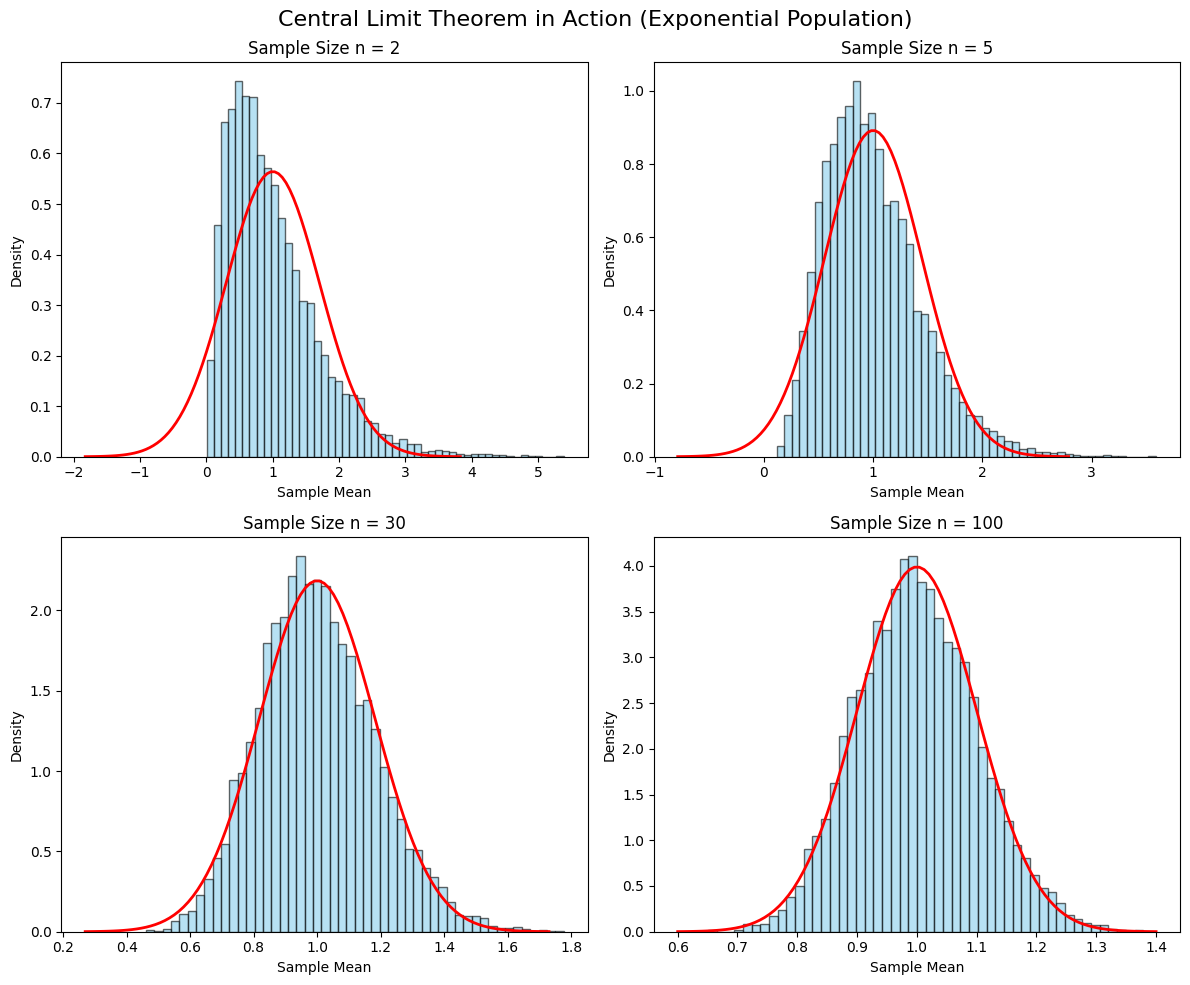

In [10]:
#given by gemini as an example for clt theorm
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Original highly skewed population: Exponential Distribution
lam = 1.0
pop_mean = 1.0 / lam

# We will try different sample sizes
sample_sizes = [2, 5, 30, 100]
n_simulations = 10000

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, n in enumerate(sample_sizes):
    # Draw n_simulations samples, each of size n
    samples = np.random.exponential(scale=1/lam, size=(n_simulations, n))
    # Calculate the mean of each sample
    sample_means = np.mean(samples, axis=1)

    # Plot histogram of sample means
    axes[i].hist(sample_means, bins=50, density=True, alpha=0.6, color='skyblue', edgecolor='black')

    # Plot theoretical normal distribution from CLT
    # CLT Mean = pop_mean, CLT Std = pop_std / sqrt(n)
    clt_mean = pop_mean
    clt_std = (1/lam) / np.sqrt(n)
    x_axis = np.linspace(clt_mean - 4*clt_std, clt_mean + 4*clt_std, 100)
    axes[i].plot(x_axis, stats.norm.pdf(x_axis, clt_mean, clt_std), 'r-', lw=2)

    axes[i].set_title(f'Sample Size n = {n}')
    axes[i].set_xlabel('Sample Mean')
    axes[i].set_ylabel('Density')

plt.suptitle('Central Limit Theorem in Action (Exponential Population)', fontsize=16)
plt.tight_layout()
plt.show()

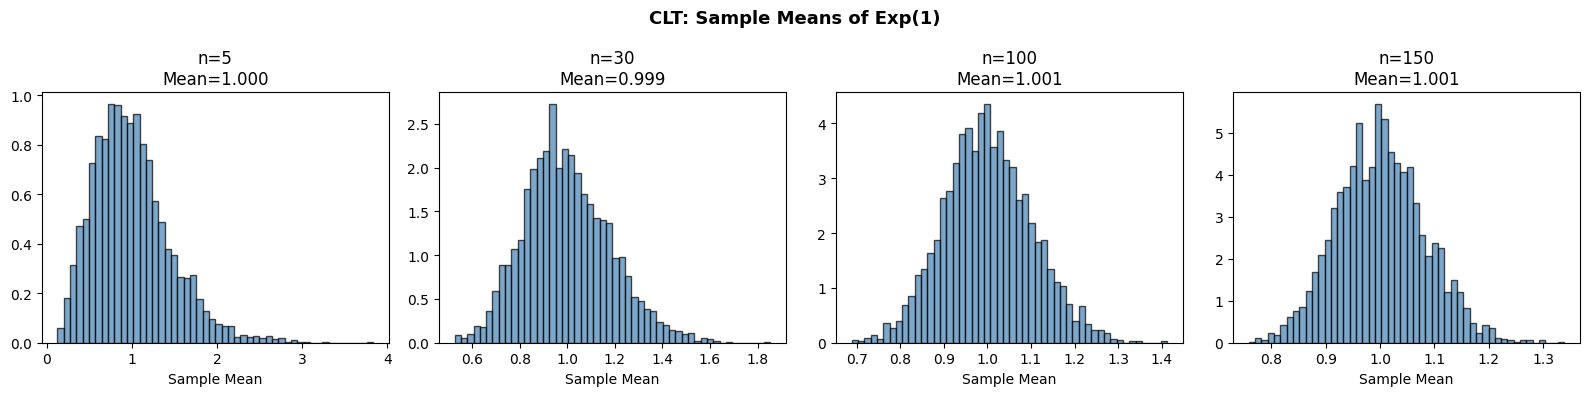

In [14]:
#clt by sir
sample_size = [5, 30, 100, 150]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, n in enumerate(sample_size):
  means = [np.mean(np.random.exponential(1, n)) for _ in range(3000)]
  axes[i].hist(means, bins=50, density=True,
               color='steelblue', edgecolor='black', alpha=0.7)
  axes[i].set_title(f'n={n}\nMean={np.mean(means):.3f}')
  axes[i].set_xlabel('Sample Mean')

fig.suptitle('CLT: Sample Means of Exp(1)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()